# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import DLRSDDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import csv
import matplotlib.pyplot as plt

## Visualize images and masks

Total number of patches: 2100


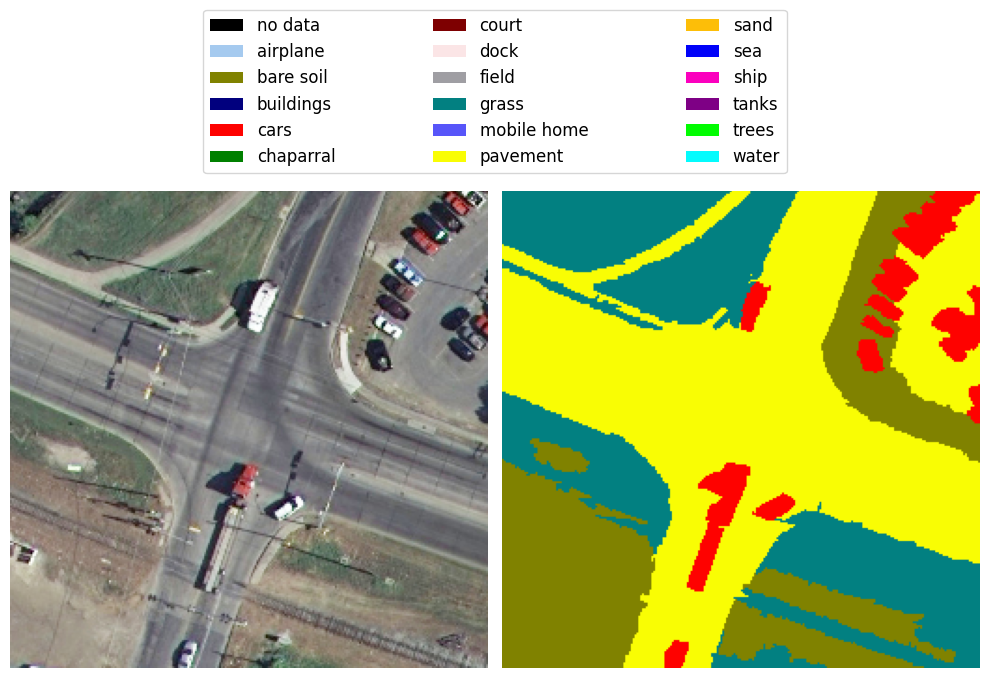

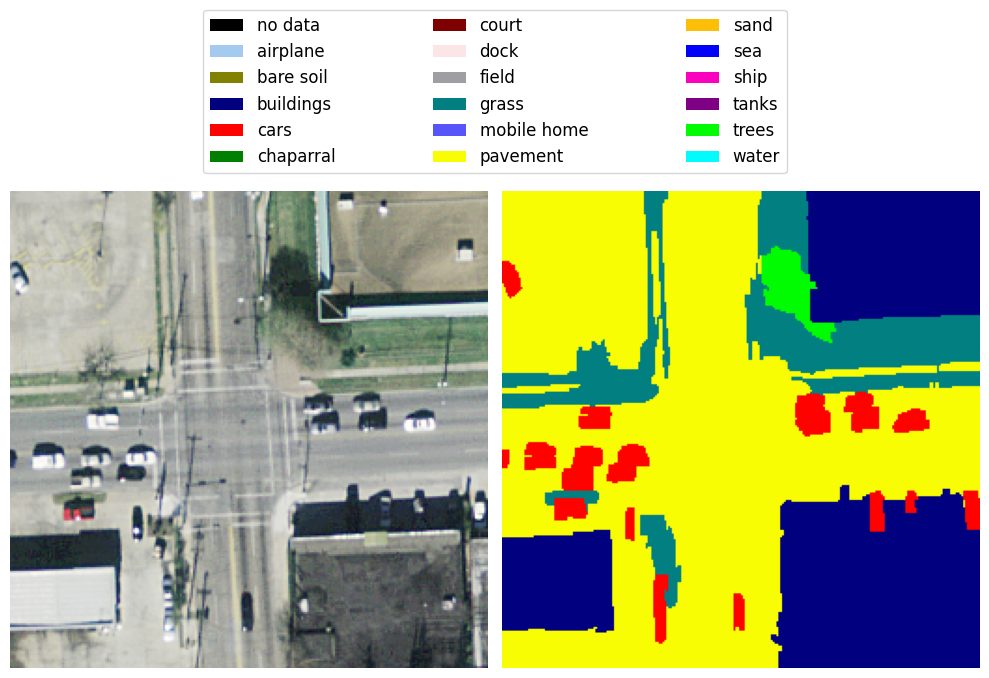

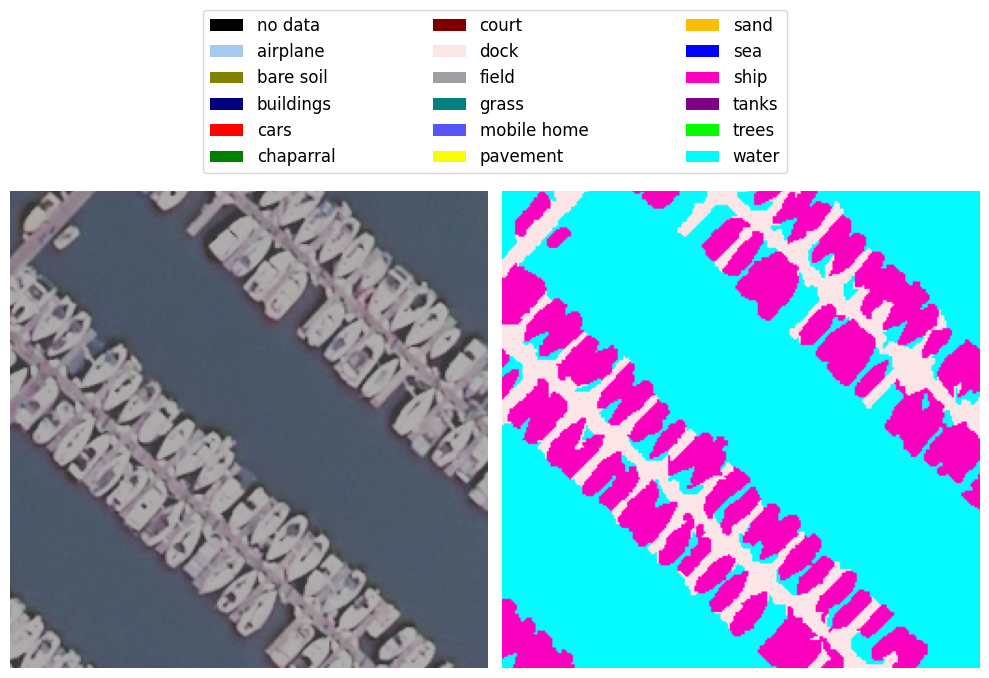

In [ ]:
dataset_config = {
    "data_dir": "./data/DLRSD"
}
dataset = DLRSDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(8);

In [24]:
dataset.data_distribution_table()

,Number of pixels
no data,0.0
airplane,448066.0
bare soil,14957125.0
buildings,13979440.0
cars,3650472.0
chaparral,3026039.0
court,1789456.0
dock,908702.0
field,6406008.0
grass,20581508.0


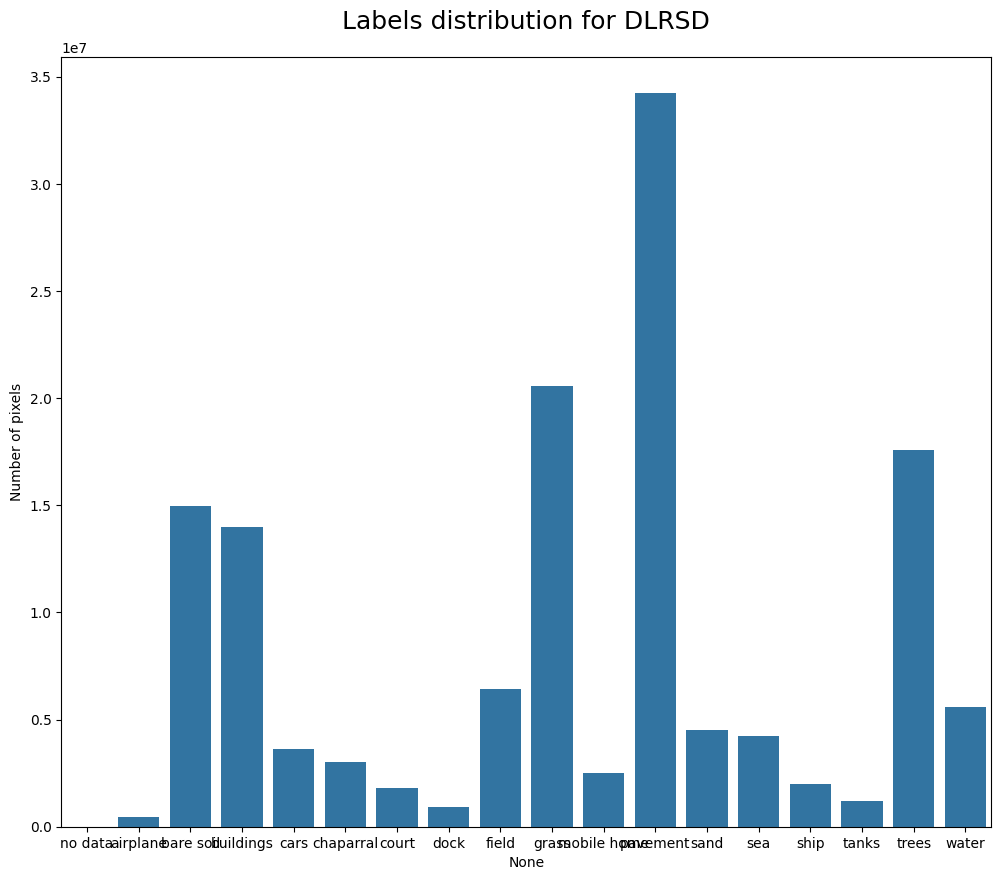

In [25]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/DLRSD",
    "csv_file": "./data/DLRSD/dlrsd_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = DLRSDDataset(train_dataset_config)
len(train_dataset)

1680

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/DLRSD"
model_config = {
    "num_classes": 18, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [28]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-03 11:43:44,288 INFO Starting training.
training: 100%|██████████| 210/210 [00:20<00:00, 10.35it/s]
2025-03-03 11:44:04,673 INFO epoch: 1, time: 20, loss:  0.82073
testing on train set: 100%|██████████| 210/210 [00:09<00:00, 22.29it/s]
2025-03-03 11:44:15,943 INFO IOU:0.37842780596477393, IOU mean:0.36835924384992075, IOU per Class:[0.         0.         0.34331908 0.43982048 0.52531175 0.39116848
 0.7452136  0.         0.93977571 0.2404452  0.0075349  0.57587511
 0.46761788 0.74842565 0.3187052  0.07658644 0.27376409 0.53690282]
training: 100%|██████████| 210/210 [00:20<00:00, 10.10it/s]
2025-03-03 11:44:36,750 INFO epoch: 2, time: 21, loss:  0.64354
testing on train set: 100%|██████████| 210/210 [00:09<00:00, 22.07it/s]
2025-03-03 11:44:46,301 INFO IOU:0.6044179371467653, IOU mean:0.4230244315524525, IOU per Class:[0.         0.         0.47674407 0.64792289 0.55956923 0.
 0.75959144 0.         0.89935439 0.58388009 0.         0.65790745
 0.37812961 0.7326374  0.47247312 0.  

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/DLRSD",
    "csv_file": "./data/DLRSD/dlrsd_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = DLRSDDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/DLRSD/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

210


2025-03-03 11:48:46,083 INFO Loading checkpoint /home/dragik/data/FAIR_EO/DLRSD/checkpoint.pth.tar
2025-03-03 11:48:46,460 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/DLRSD/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 53/53 [00:01<00:00, 30.31it/s]


[{'IOU': 0.708115798573103,
  'IOU mean': 0.5403117581190399,
  'IOU per Class': array([0.        , 0.        , 0.57481883, 0.77427963, 0.6211691 ,
         0.        , 0.79836347, 0.        , 1.        , 0.70103855,
         0.62098407, 0.81751917, 0.68135393, 0.93467455, 0.69143494,
         0.        , 0.69678693, 0.81318847])}]

## Predictions

2025-03-03 11:52:11,730 INFO Loading checkpoint /home/dragik/data/FAIR_EO/DLRSD/checkpoint.pth.tar
2025-03-03 11:52:12,099 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/DLRSD/checkpoint.pth.tar at epoch 11


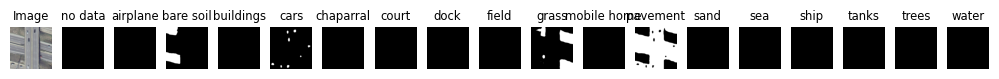

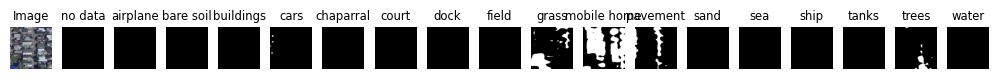

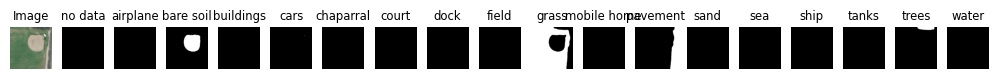

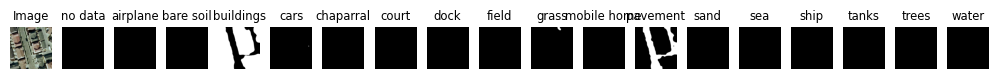

In [ ]:
model_path = "./data/DLRSD/checkpoint.pth.tar"
labels = ["no data","airplane","bare soil","buildings","cars","chaparral","court","dock","field","grass","mobile home","pavement","sand","sea","ship","tanks","trees","water"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})
csv_file = "./data/DLRSD/dlrsd_test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/DLRSD/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/DLRSD/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/DLRSD/' + test_list[12])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/DLRSD/' + test_list[50])
fig = model.predict_masks(image, labels, transform)